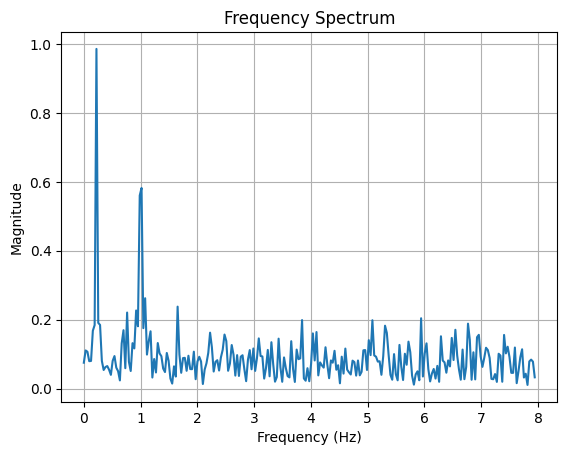

which file number?10


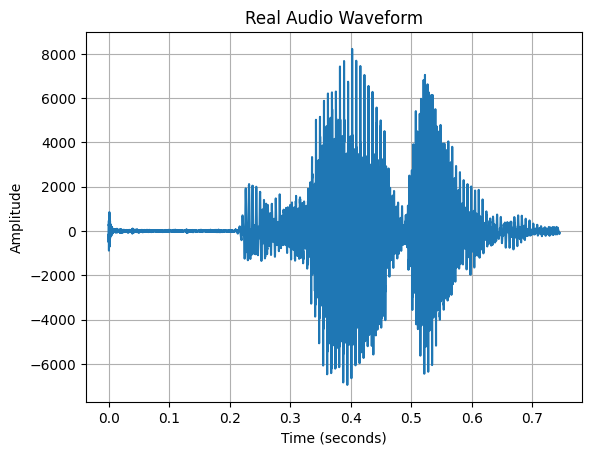

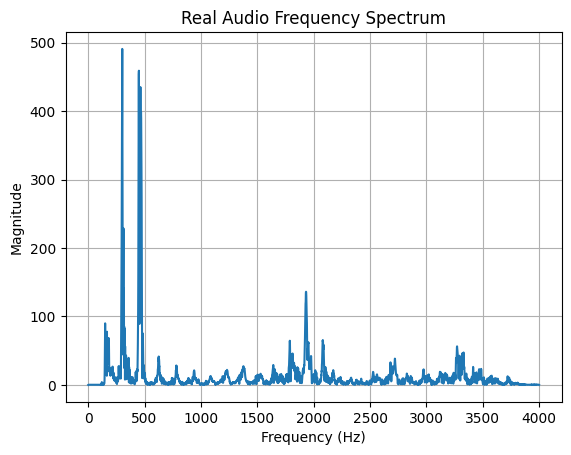

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random

# Starting graph
phi = 0 #float(input("Shift?"))
lamda = 1 #float(input("Wavelength?"))
k = 2*math.pi/lamda
A = 1 # float(input("Amplitude?"))
totaltime = 10*math.pi #float(input("Total time?"))
total_interval = 501


time = np.linspace(0 , totaltime , total_interval)
dt = time[1]-time[0]
position = []

for t in time:
  wave = A*math.sin(k*t+phi)
  position.append(wave)



#Noise
noise_strength = 1
position_noise_rand = noise_strength * np.random.randn(total_interval)


#additional graphs
phi_add_1 = random.randint(0,12)/6*math.pi
lamda_add_1 = random.randint(20,30)/5
k_add_1 = 2*math.pi/lamda_add_1
A_add_1 = random.uniform(1,2)


position_add_1 = []
for t in time:
  wave = A_add_1*math.sin(k_add_1*t+phi_add_1)
  position_add_1.append(wave)



#Combination graph
position_combined = []

n = 0
while n < total_interval:
  new_position = position[n]+position_noise_rand[n]+position_add_1[n]
  position_combined.append(new_position)
  n+=1


#Fourier decoding
signal = np.array(position_combined)
fft_values = np.fft.rfft(signal)
frequencies = np.fft.rfftfreq(len(signal),d=dt)

#magnitudes = np.abs(fft_values)
magnitudes = np.abs(fft_values) / len(signal)
magnitudes[1:-1] *= 2


#graphing
plt.plot(frequencies, magnitudes)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Spectrum")
plt.grid(True)
plt.show()







# ==========================================
# REAL-WORLD DATA: AUDIO FREQUENCY ANALYSIS
# ==========================================

# Download 0_george_11.wav from:
# https://raw.githubusercontent.com/Jakobovski/free-spoken-digit-dataset/master/recordings/0_george_11.wav



from scipy.io import wavfile

file_number = input("which file number?")
# Load audio file
sample_rate, audio = wavfile.read("recordings_0_george_"+file_number+".wav")

# Convert stereo to mono if necessary
if audio.ndim == 2:
    audio = audio.mean(axis=1)

audio = audio.astype(float)
audio -= np.mean(audio)

# Plot audio waveform
audio_time = np.arange(len(audio)) / sample_rate

plt.figure()
plt.plot(audio_time, audio)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Real Audio Waveform")
plt.grid(True)
plt.show()

# Fourier analysis
audio_fft = np.fft.rfft(audio)
audio_frequencies = np.fft.rfftfreq(
    len(audio), d=1/sample_rate
)

audio_magnitudes = np.abs(audio_fft) / len(audio)

if len(audio) % 2 == 0:
    audio_magnitudes[1:-1] *= 2
else:
    audio_magnitudes[1:] *= 2

# Plot frequency spectrum
plt.figure()
plt.plot(audio_frequencies, audio_magnitudes)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Real Audio Frequency Spectrum")
plt.grid(True)
plt.show()